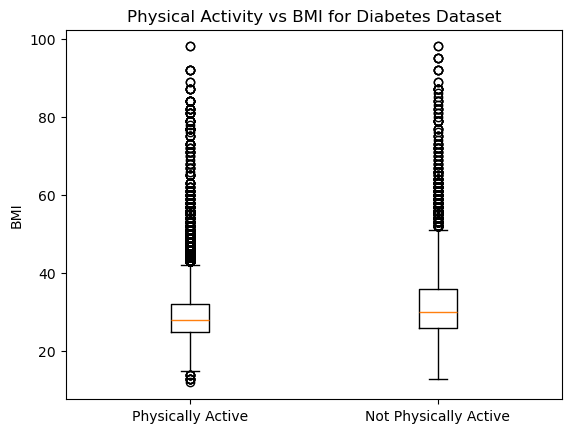

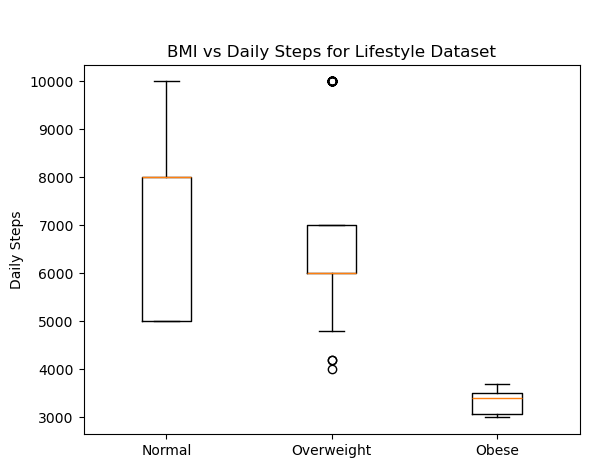



Intercept of steps vs heart rate:  70.69390378778708
Slope for steps vs heart rate:  -7.747402103642453e-05
R^2 for steps vs heart rate:  0.0009186097365408985


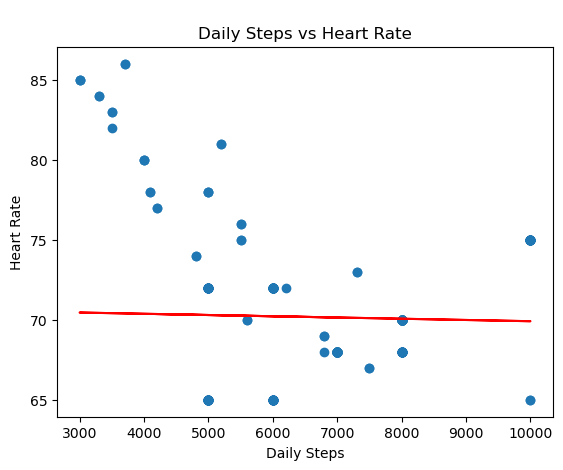



Intercept of steps vs blood pressure:  125.17981435207952
Slope for steps vs blood pressure:  0.0004949007383103597
R^2 for steps vs blood pressure:  0.010679614298460316


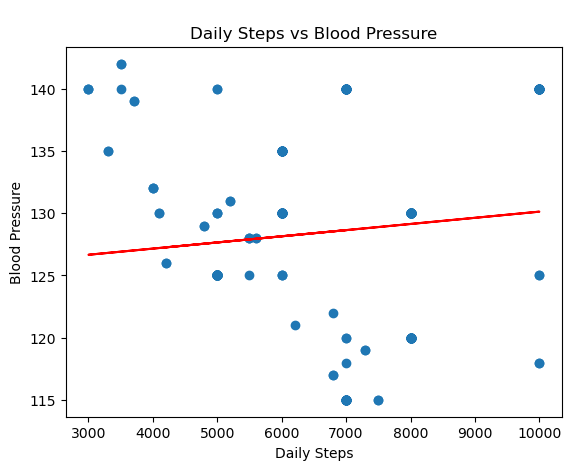



chi squared for alcohol vs diabetes:  635.0865339749427
p value for alcohol vs diabetes:  3.9133962745676324e-140
degrees of freedom for alcohol vs diabetes:  1
expected value for alcohol vs diabetes:  [[33836. 33836.]
 [ 1510.  1510.]]


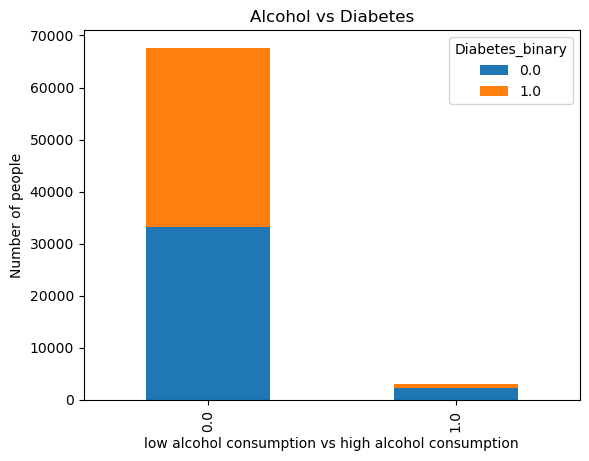



chi squared for smoking vs diabetes:  522.4810772937883
p value for smoking vs diabetes:  1.2211053080400827e-115
degrees of freedom for smoking vs diabetes:  1
expected value for smoking vs diabetes:  [[18547. 18547.]
 [16799. 16799.]]


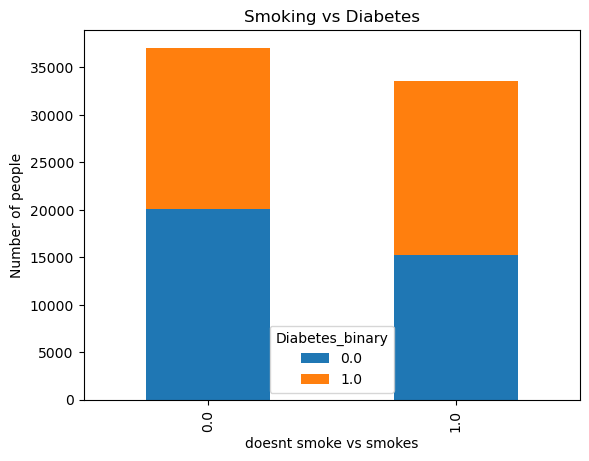

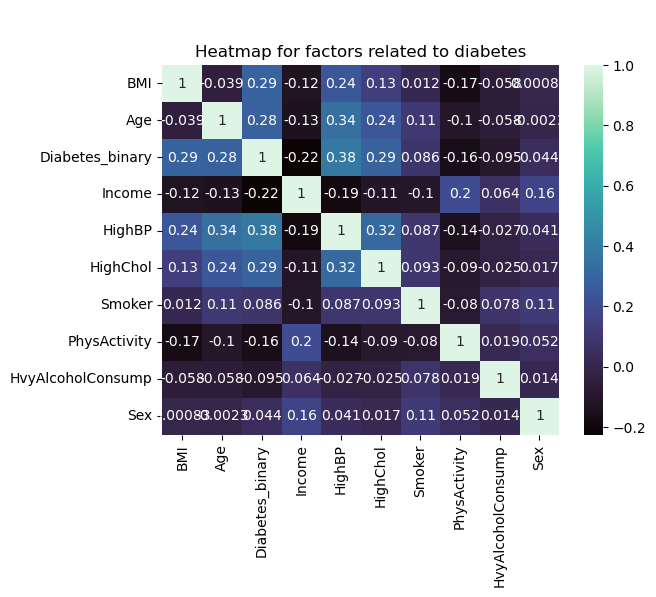

              precision    recall  f1-score   support

         0.0       0.74      0.67      0.70     10671
         1.0       0.69      0.76      0.72     10537

    accuracy                           0.71     21208
   macro avg       0.71      0.71      0.71     21208
weighted avg       0.71      0.71      0.71     21208

[['BMI' 0.018912964830714214]
 ['Age' 0.04073689764908499]
 ['Income' -0.24259172781381616]
 ['HighBP' 1.004318814135789]
 ['HighChol' 0.6611733065712722]
 ['Smoker' -0.01669940705893615]
 ['PhysActivity' -0.6156160129551876]
 ['HvyAlcoholConsump' -0.9700428335413885]
 ['Sex' 0.254065220038319]]


In [57]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as stats
import seaborn as sns
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
from scipy import stats
from scipy.stats import chi2_contingency 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

# load both of my datasets
diabetes = pd.read_csv('diabetes_health_indicators.csv')
lifestyle = pd.read_csv('lifestyle.csv')

# cleaning both datasetes by replacing missing values of appropriate cols with means
diabetes["BMI"] = diabetes["BMI"].fillna(diabetes["BMI"].mean())
diabetes["Age"] = diabetes["Age"].fillna(diabetes["Age"].mean())
diabetes["Income"] = diabetes["Income"].fillna(diabetes["Income"].mean())

lifestyle["Heart Rate"] = lifestyle["Heart Rate"].fillna(lifestyle["Heart Rate"].mean())
lifestyle["Daily Steps"] = lifestyle["Daily Steps"].fillna(lifestyle["Daily Steps"].mean())
lifestyle["Sleep Duration"] = lifestyle["Sleep Duration"].fillna(lifestyle["Sleep Duration"].mean())
lifestyle["Quality of Sleep"] = lifestyle["Quality of Sleep"].fillna(lifestyle["Quality of Sleep"].mean())
lifestyle["Stress Level"] = lifestyle["Stress Level"].fillna(lifestyle["Stress Level"].mean())
lifestyle["Physical Activity Level"] = lifestyle["Physical Activity Level"].fillna(lifestyle["Physical Activity Level"].mean())

# cleaning both datasetes by removing missing rows from columns with binary values
diabetes = diabetes.dropna(subset = ["Diabetes_binary","HighBP","HighChol","Smoker","PhysActivity","HvyAlcoholConsump","Sex"])
lifestyle = lifestyle.dropna(subset = ["BMI Category","Blood Pressure","Gender"])

# boxplots for physical activity/daily steps vs bmi for both of my datasets
exerciseGroup = diabetes[diabetes["PhysActivity"] == 1]["BMI"]
noExerciseGroup = diabetes[diabetes["PhysActivity"] == 0]["BMI"]

plt.figure()
plt.boxplot([exerciseGroup, noExerciseGroup], tick_labels=['Physically Active', 'Not Physically Active'])
plt.title("Physical Activity vs BMI for Diabetes Dataset")
plt.ylabel("BMI")
plt.show()

normalGroup = lifestyle[lifestyle["BMI Category"] == "Normal"]["Daily Steps"]
overweightGroup = lifestyle[lifestyle["BMI Category"] == "Overweight"]["Daily Steps"]
obeseGroup = lifestyle[lifestyle["BMI Category"] == "Obese"]["Daily Steps"]

plt.figure()
plt.boxplot([normalGroup, overweightGroup, obeseGroup], tick_labels=['Normal', 'Overweight','Obese'])
plt.title("\n\nBMI vs Daily Steps for Lifestyle Dataset")
plt.ylabel("Daily Steps")
plt.show()

# using linear regression to plot scatterplots for daily steps vs heart rate 
x = lifestyle[["Daily Steps"]]
yHeart = lifestyle["Heart Rate"]

regHeart = LinearRegression()
regHeart.fit(x,yHeart)

interceptHeart = regHeart.intercept_
slopeHeart = regHeart.coef_[0]
rSquaredHeart = regHeart.score(x,yHeart)

print("\n\nIntercept of steps vs heart rate: ", interceptHeart)
print("Slope for steps vs heart rate: ", slopeHeart)
print("R^2 for steps vs heart rate: ", rSquaredHeart)

modelledDependentHeart = np.polyval([slopeHeart, interceptHeart], x)
plt.scatter(x, yHeart)
plt.plot(x, modelledDependentHeart, color = 'red')
plt.title("\nDaily Steps vs Heart Rate")
plt.xlabel("Daily Steps")
plt.ylabel("Heart Rate")
plt.show()

# using linear regression to plot scatterplots for daily steps vs blood pressure
lifestyle["BP"] = lifestyle["Blood Pressure"].str.split("/").str[0].astype(float)
yBp = lifestyle["BP"]

regBp = LinearRegression()
regBp.fit(x,yBp)

interceptBp = regBp.intercept_
slopeBp = regBp.coef_[0]
rSquaredBp = regBp.score(x,yBp)

print("\n\nIntercept of steps vs blood pressure: ", interceptBp)
print("Slope for steps vs blood pressure: ", slopeBp)
print("R^2 for steps vs blood pressure: ", rSquaredBp)

modelledDependentBp = np.polyval([slopeBp, interceptBp], x)
plt.scatter(x, yBp)
plt.plot(x, modelledDependentBp, color = 'red')
plt.title("\nDaily Steps vs Blood Pressure")
plt.xlabel("Daily Steps")
plt.ylabel("Blood Pressure")
plt.show()

# chi square of alcohol vs diabetes
alcoholTable = pd.crosstab(diabetes["HvyAlcoholConsump"],diabetes["Diabetes_binary"]) 
aChiSqr, apVal, aDof, aExpectVal = chi2_contingency(alcoholTable)
print("\n\nchi squared for alcohol vs diabetes: ", aChiSqr)
print("p value for alcohol vs diabetes: ", apVal)
print("degrees of freedom for alcohol vs diabetes: ", aDof)
print("expected value for alcohol vs diabetes: ", aExpectVal)

# stacked bar chart for alcohol vs diabetes
alcoholTable.plot(kind='bar', stacked=True, title="Alcohol vs Diabetes")
plt.xlabel("low alcohol consumption vs high alcohol consumption")
plt.ylabel("Number of people")
plt.show()

# chi square test for smoking vs diabetes
smokeTable = pd.crosstab(diabetes["Smoker"],diabetes["Diabetes_binary"]) 
sChiSqr, spVal, sDof, sExpectVal = chi2_contingency(smokeTable)
print("\n\nchi squared for smoking vs diabetes: ", sChiSqr)
print("p value for smoking vs diabetes: ", spVal)
print("degrees of freedom for smoking vs diabetes: ", sDof)
print("expected value for smoking vs diabetes: ", sExpectVal)

# stacked bar chart for smoking vs diabetes
smokeTable.plot(kind='bar', stacked=True, title="Smoking vs Diabetes")
plt.xlabel("doesnt smoke vs smokes")
plt.ylabel("Number of people")
plt.show()

# making a correlation heatmap for the diabetes dataset
heatmapCols = ["BMI","Age","Diabetes_binary","Income","HighBP","HighChol","Smoker","PhysActivity","HvyAlcoholConsump","Sex"]
cMatrix = diabetes[heatmapCols].corr()
sns.heatmap(cMatrix, cmap = "mako", annot=True)
plt.title("\n\nHeatmap for factors related to diabetes")
plt.show()

# logistic regression for the diabetes factors (the part was based off the lab example code)
X = diabetes[["BMI","Age","Income","HighBP","HighChol","Smoker","PhysActivity","HvyAlcoholConsump","Sex"]] 
y = diabetes["Diabetes_binary"]

xTrain, xTest, yTrain, yTest = train_test_split(X, y, test_size=0.3, random_state=25)
logistic = LogisticRegression(fit_intercept=False)
logistic.fit(xTrain, yTrain)
yPred = logistic.predict(xTest)

confusion = confusion_matrix(yTest, yPred)
print(classification_report(yTest, yPred))

coef = np.column_stack((X.columns, logistic.coef_[0]))
print(coef)